In [1]:
import numpy as np

# Number of AC units to simulate in your model
num_units = 10000 

# --- Fixed AC Units (Target Mean: 12 years) ---
# For a shape (k) of 3.5, the scale (lambda) needs to be ~13.3 to get a mean of 12.
fixed_shape = 3.5
fixed_scale = 13.3
fixed_lifespans = np.random.weibull(fixed_shape, num_units) * fixed_scale

# --- Portable AC Units (Target Mean: 7.5 years) ---
# For a shape (k) of 3.5, the scale (lambda) needs to be ~8.33 to get a mean of 7.5.
portable_shape = 3.5
portable_scale = 8.33
portable_lifespans = np.random.weibull(portable_shape, num_units) * portable_scale

# --- Print the results to verify ---
print(f"Fixed AC Mean Lifetime: {np.mean(fixed_lifespans):.2f} years")
print(f"Portable AC Mean Lifetime: {np.mean(portable_lifespans):.2f} years")

Fixed AC Mean Lifetime: 11.98 years
Portable AC Mean Lifetime: 7.49 years


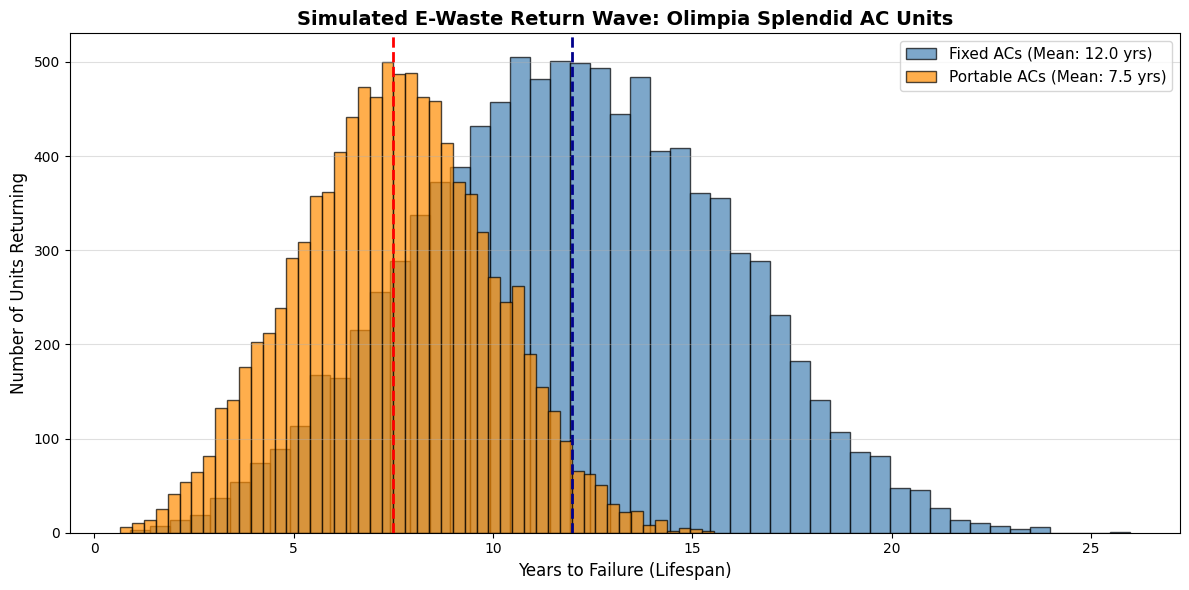

In [2]:
import matplotlib.pyplot as plt

# --- Plot the Histograms ---
# Set up the figure size
plt.figure(figsize=(12, 6))

# Plot Fixed ACs (alpha=0.7 makes it slightly transparent so you can see overlaps)
plt.hist(fixed_lifespans, bins=50, alpha=0.7, label=f'Fixed ACs (Mean: {np.mean(fixed_lifespans):.1f} yrs)', color='steelblue', edgecolor='black')

# Plot Portable ACs
plt.hist(portable_lifespans, bins=50, alpha=0.7, label=f'Portable ACs (Mean: {np.mean(portable_lifespans):.1f} yrs)', color='darkorange', edgecolor='black')

# --- Format the Chart ---
plt.title('Simulated E-Waste Return Wave: Olimpia Splendid AC Units', fontsize=14, fontweight='bold')
plt.xlabel('Years to Failure (Lifespan)', fontsize=12)
plt.ylabel('Number of Units Returning', fontsize=12)

# Add dashed vertical lines to show the exact mean for each
plt.axvline(np.mean(fixed_lifespans), color='darkblue', linestyle='dashed', linewidth=2)
plt.axvline(np.mean(portable_lifespans), color='red', linestyle='dashed', linewidth=2)

# Add a grid and legend for readability
plt.grid(axis='y', alpha=0.4)
plt.legend(fontsize=11)

# Display the plot
plt.tight_layout()
plt.show()

Failures in Year 1: 3.0%
Overall Mean Lifespan: 9.77 years


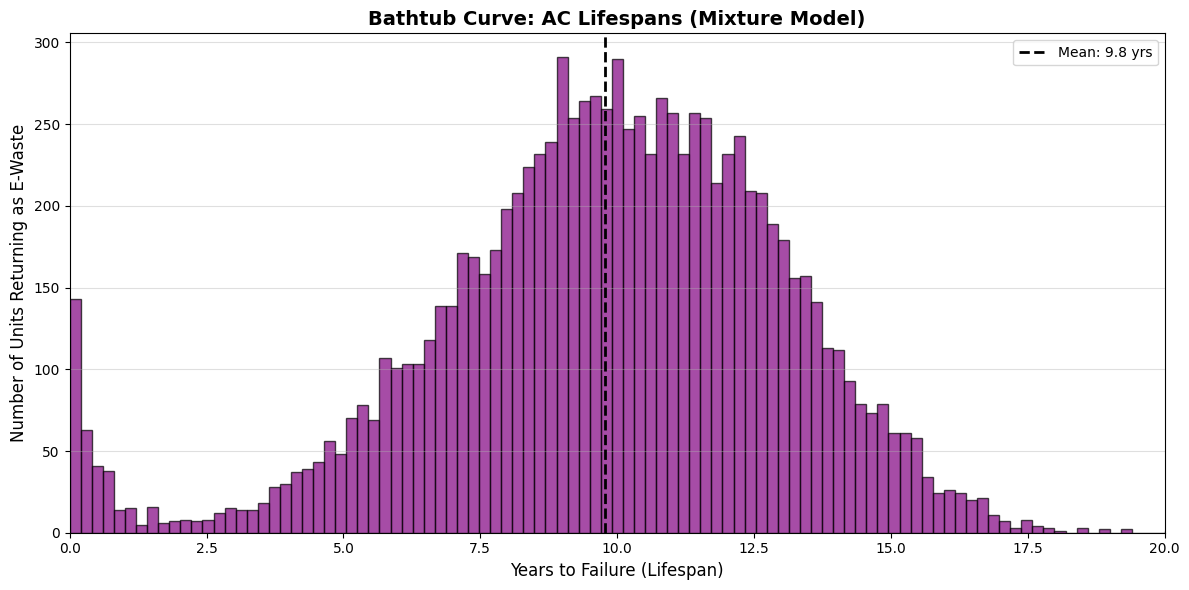

In [3]:

# Total units in the simulation
num_units = 10000

# We want roughly 3% to die in year 1. 
# Let's say 3.5% of units are from a "defective" batch that die very quickly.
defect_rate = 0.035 
num_defective = int(num_units * defect_rate)
num_normal = num_units - num_defective

# 1. Simulate the Early Failures (Infant Mortality)
# k < 1 creates a curve where failures drop off sharply. 
# A small scale means they die fast.
early_shape = 0.8
early_scale = 0.5
early_lifespans = np.random.weibull(early_shape, num_defective) * early_scale

# 2. Simulate the Normal Units (Wear-Out)
# k = 4.0 creates that nice "wave" of wear-out failures.
# Scale = 11.1 pushes the mean of this specific group to about 10.
normal_shape = 4.0
normal_scale = 11.1
normal_lifespans = np.random.weibull(normal_shape, num_normal) * normal_scale

# 3. Combine them into your final value chain model
all_lifespans = np.concatenate((early_lifespans, normal_lifespans))

# --- Verification Metrics ---
year_one_failures = np.sum(all_lifespans <= 1.0) / num_units * 100
overall_mean = np.mean(all_lifespans)

print(f"Failures in Year 1: {year_one_failures:.1f}%")
print(f"Overall Mean Lifespan: {overall_mean:.2f} years")

# --- Plot the Histogram ---
plt.figure(figsize=(12, 6))

# We use more bins here (e.g., 100) to clearly see the year 1 spike
plt.hist(all_lifespans, bins=100, color='purple', edgecolor='black', alpha=0.7)

plt.title('Bathtub Curve: AC Lifespans (Mixture Model)', fontsize=14, fontweight='bold')
plt.xlabel('Years to Failure (Lifespan)', fontsize=12)
plt.ylabel('Number of Units Returning as E-Waste', fontsize=12)

# Mark the mean
plt.axvline(overall_mean, color='black', linestyle='dashed', linewidth=2, label=f'Mean: {overall_mean:.1f} yrs')

plt.xlim(0, 20) # Limit x-axis to 20 years to zoom in on the relevant data
plt.grid(axis='y', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()